In [18]:

from pathlib import Path

dataset_path = Path("NUS Hand Posture dataset-II")

hand_path = dataset_path / "Hand Postures"

for class_name in sorted(set(p.name[0] for p in hand_path.glob("*.jpg"))):
    images = list(hand_path.glob(f"{class_name}*.jpg"))
    print(f"{class_name} 클래스: {len(images)}장")

print("전체 이미지:", len(list(hand_path.glob("*.jpg"))))


a 클래스: 200장
b 클래스: 200장
c 클래스: 200장
d 클래스: 200장
e 클래스: 200장
f 클래스: 200장
g 클래스: 200장
h 클래스: 200장
i 클래스: 200장
j 클래스: 200장
전체 이미지: 2000


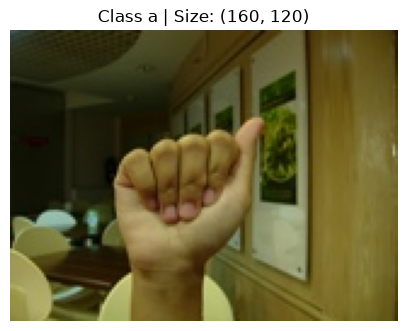

In [19]:

import matplotlib.pyplot as plt
from PIL import Image

# a 클래스 이미지 1장 확인
image_path = next(hand_path.glob("a*.jpg"))

image = Image.open(image_path)

plt.figure(figsize=(5, 4))
plt.imshow(image)
plt.title(f"Class a | Size: {image.size}")
plt.axis("off")
plt.show()


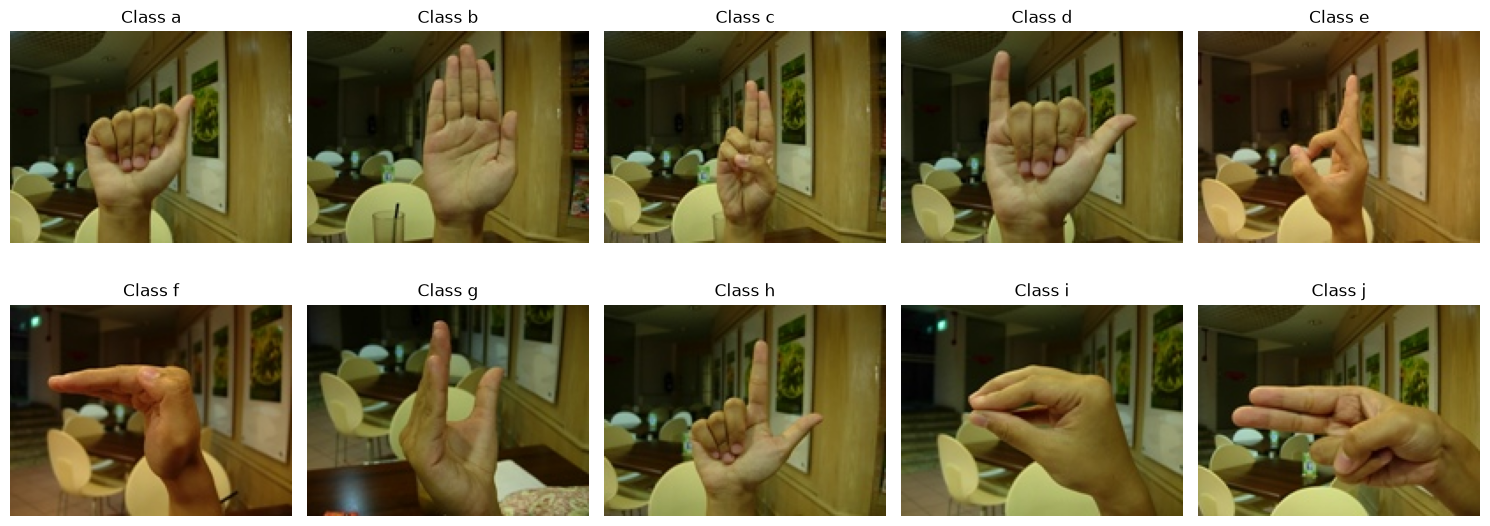

In [20]:

import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for i, ax in enumerate(axes.flat):
    class_name = chr(ord('a') + i)
    image_path = next(hand_path.glob(f"{class_name}*.jpg"))
    
    image = Image.open(image_path)
    ax.imshow(image)
    ax.set_title(f"Class {class_name}")
    ax.axis("off")

plt.tight_layout()
plt.show()


In [21]:

print("이미지 폴더:", hand_path)
print("폴더 존재:", hand_path.exists())
print("이미지 예시:", [p.name for p in list(hand_path.glob("*.jpg"))[:5]])


이미지 폴더: NUS Hand Posture dataset-II\Hand Postures
폴더 존재: True
이미지 예시: ['a (1).jpg', 'a (10).jpg', 'a (100).jpg', 'a (101).jpg', 'a (102).jpg']


In [22]:
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

In [23]:

from torch.utils.data import Dataset, random_split
from PIL import Image
import torch

class HandDataset(Dataset):
    def __init__(self, folder, transform=None):
        self.files = list(folder.glob("*.jpg"))
        self.transform = transform

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        path = self.files[idx]
        image = Image.open(path).convert("RGB")
        label = ord(path.name[0]) - ord("a")

        if self.transform:
            image = self.transform(image)

        return image, label

dataset = HandDataset(hand_path, transform=transform)

train_dataset, val_dataset, test_dataset = random_split(
    dataset, [1400, 300, 300]
)

print("학습:", len(train_dataset))
print("검증:", len(val_dataset))
print("테스트:", len(test_dataset))


학습: 1400
검증: 300
테스트: 300


In [24]:
from torch.utils.data import DataLoader

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print("학습 묶음 수:", len(train_loader))
print("검증 묶음 수:", len(val_loader))
print("테스트 묶음 수:", len(test_loader))

학습 묶음 수: 44
검증 묶음 수: 10
테스트 묶음 수: 10


In [25]:

import torchvision.models as models

print("ResNet18:", models.resnet18)
print("MobileNetV2:", models.mobilenet_v2)
print("EfficientNet-B0:", models.efficientnet_b0)


ResNet18: <function resnet18 at 0x000002C99A1D1900>
MobileNetV2: <function mobilenet_v2 at 0x000002C99A18AE50>
EfficientNet-B0: <function efficientnet_b0 at 0x000002C99A1428D0>


In [26]:

model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

print("ResNet18 모델 준비 완료!")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\mbc/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 51.6MB/s]


ResNet18 모델 준비 완료!


In [27]:

import torch.nn as nn

model.fc = nn.Linear(model.fc.in_features, 10)

print("출력 클래스:", model.fc.out_features)


출력 클래스: 10


In [28]:

import torch.optim as optim

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

print("학습 준비 완료!")


학습 준비 완료!


In [29]:

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("학습 장치:", device)


학습 장치: cuda


In [30]:

model = model.to(device)

print("모델 이동 완료!")


모델 이동 완료!


In [31]:

model.train()

for images, labels in train_loader:
    images = images.to(device)
    labels = labels.to(device)

    optimizer.zero_grad()
    outputs = model(images)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer.step()

print("첫 번째 학습 완료!")


첫 번째 학습 완료!


In [32]:

model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"검증 정확도: {accuracy:.2f}%")


검증 정확도: 48.67%


In [33]:

for epoch in range(2, 6):
    model.train()

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

    print(f"Epoch {epoch} 완료!")


Epoch 2 완료!
Epoch 3 완료!
Epoch 4 완료!
Epoch 5 완료!


In [34]:

for epoch in range(2, 6):
    model.train()

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

    print(f"Epoch {epoch} 완료!")


Epoch 2 완료!
Epoch 3 완료!
Epoch 4 완료!
Epoch 5 완료!


In [35]:

model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"검증 정확도: {accuracy:.2f}%")


검증 정확도: 87.67%


In [36]:

for param in model.parameters():
    param.requires_grad = False

for param in model.layer4.parameters():
    param.requires_grad = True

for param in model.fc.parameters():
    param.requires_grad = True

print("학습 가능하도록 설정된 부분:")
print("layer4 + fc")


학습 가능하도록 설정된 부분:
layer4 + fc


In [37]:

optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.0001
)

print("학습률 변경 완료!")


학습률 변경 완료!


In [38]:

for epoch in range(1, 6):
    model.train()

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

    print(f"Fine-tuning Epoch {epoch} 완료!")


Fine-tuning Epoch 1 완료!
Fine-tuning Epoch 2 완료!
Fine-tuning Epoch 3 완료!
Fine-tuning Epoch 4 완료!
Fine-tuning Epoch 5 완료!


In [39]:

model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"검증 정확도: {accuracy:.2f}%")


검증 정확도: 100.00%


In [40]:

model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total

print(f"최종 테스트 정확도: {test_accuracy:.2f}%")


최종 테스트 정확도: 100.00%


In [41]:
# 혼동행렬

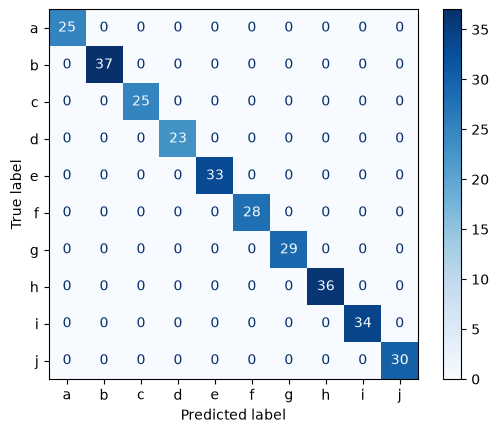

In [42]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

all_labels = []
all_preds = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.numpy())
        all_preds.extend(predicted.cpu().numpy())

cm = confusion_matrix(all_labels, all_preds)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list("abcdefghij")
)

disp.plot(cmap="Blues")
plt.show()

# 세로축(True label): 실제 정답
# 가로축(Predicted label): AI가 예측한 답


In [43]:

from sklearn.metrics import classification_report

print(classification_report(
    all_labels,
    all_preds,
    labels=list(range(10)),
    target_names=list("abcdefghij"),
    digits=4
))

# 지표	점수
# Accuracy (정확도)	97.00%
# Precision (정밀도)	96.77%
# Recall (재현율)	97.33%
# F1-score	96.98%

              precision    recall  f1-score   support

           a     1.0000    1.0000    1.0000        25
           b     1.0000    1.0000    1.0000        37
           c     1.0000    1.0000    1.0000        25
           d     1.0000    1.0000    1.0000        23
           e     1.0000    1.0000    1.0000        33
           f     1.0000    1.0000    1.0000        28
           g     1.0000    1.0000    1.0000        29
           h     1.0000    1.0000    1.0000        36
           i     1.0000    1.0000    1.0000        34
           j     1.0000    1.0000    1.0000        30

    accuracy                         1.0000       300
   macro avg     1.0000    1.0000    1.0000       300
weighted avg     1.0000    1.0000    1.0000       300



In [44]:

train_losses = []
val_losses = []

print("Loss 기록 준비 완료!")


Loss 기록 준비 완료!


In [45]:

for epoch in range(1, 6):
    model.train()
    running_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    train_losses.append(epoch_loss)

    print(f"Epoch {epoch} Loss: {epoch_loss:.4f}")


Epoch 1 Loss: 0.0023
Epoch 2 Loss: 0.0018
Epoch 3 Loss: 0.0015
Epoch 4 Loss: 0.0012
Epoch 5 Loss: 0.0010


In [46]:

model.eval()
running_loss = 0

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        running_loss += loss.item()

val_loss = running_loss / len(val_loader)
val_losses.append(val_loss)

print(f"검증 Loss: {val_loss:.4f}")


검증 Loss: 0.0073


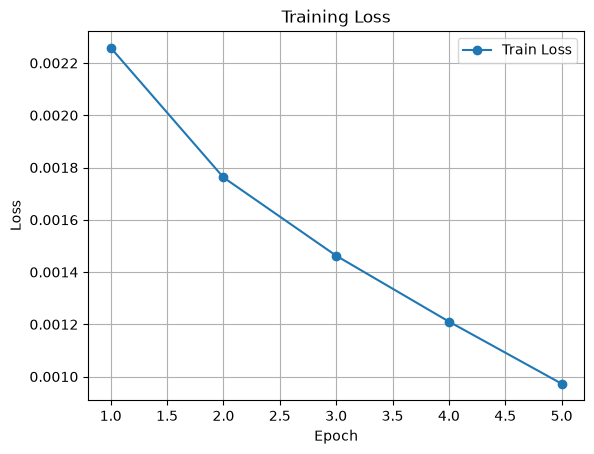

In [47]:

plt.plot(range(1, 6), train_losses, marker="o", label="Train Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.legend()
plt.grid()
plt.show()


In [48]:

train_losses = []
val_losses = []

for epoch in range(1, 6):
    model.train()
    running_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    train_losses.append(running_loss / len(train_loader))

    model.eval()
    running_val_loss = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item()

    val_losses.append(running_val_loss / len(val_loader))

    print(f"Epoch {epoch} | Train: {train_losses[-1]:.4f} | Val: {val_losses[-1]:.4f}")


Epoch 1 | Train: 0.0011 | Val: 0.0073
Epoch 2 | Train: 0.0008 | Val: 0.0060
Epoch 3 | Train: 0.0010 | Val: 0.0059
Epoch 4 | Train: 0.0006 | Val: 0.0056
Epoch 5 | Train: 0.0005 | Val: 0.0055


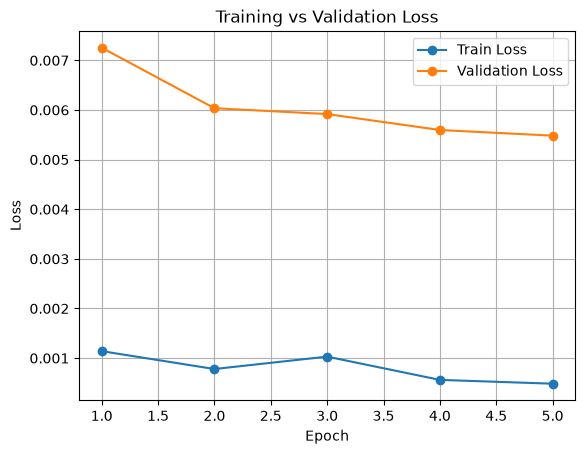

In [49]:

plt.plot(range(1, 6), train_losses, marker="o", label="Train Loss")
plt.plot(range(1, 6), val_losses, marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid()
plt.show()

# 파란색: 학습 손실
# 주황색: 검증 손실
# 두 그래프의 차이가 크다 → 학습 이미지에서는 매우 잘 맞히지만, 검증 이미지에서는 상대적으로 어려워한다는 뜻


In [50]:

# MobileNetV2 사전학습 모델 불러오기
model_mobilenet = models.mobilenet_v2(
    weights=models.MobileNet_V2_Weights.DEFAULT
)

# 마지막 출력층을 10개 손동작 분류로 변경
model_mobilenet.classifier[1] = nn.Linear(
    model_mobilenet.classifier[1].in_features, 10
)

# GPU로 모델 이동
model_mobilenet = model_mobilenet.to(device)

print("MobileNetV2 모델 준비 완료!")


Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to C:\Users\mbc/.cache\torch\hub\checkpoints\mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 49.3MB/s]


MobileNetV2 모델 준비 완료!


In [51]:

# 손동작 분류 오차 계산
criterion = nn.CrossEntropyLoss()

# 마지막 출력층만 학습하도록 설정
optimizer_mobilenet = optim.Adam(
    model_mobilenet.classifier.parameters(),
    lr=0.001
)

print("MobileNetV2 학습 준비 완료!")


MobileNetV2 학습 준비 완료!


In [52]:

# MobileNetV2 학습 시작
model_mobilenet.train()

for images, labels in train_loader:
    images = images.to(device)
    labels = labels.to(device)

    optimizer_mobilenet.zero_grad()
    outputs = model_mobilenet(images)
    loss = criterion(outputs, labels)
    loss.backward()
    optimizer_mobilenet.step()

print("MobileNetV2 첫 학습 완료!")


MobileNetV2 첫 학습 완료!


In [53]:

# 검증 모드로 변경
model_mobilenet.eval()

correct = 0
total = 0

# 검증 중에는 모델을 학습하지 않음
with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model_mobilenet(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"MobileNetV2 검증 정확도: {accuracy:.2f}%")


MobileNetV2 검증 정확도: 55.67%


In [54]:

# MobileNetV2 추가 학습 5회
for epoch in range(2, 7):
    model_mobilenet.train()

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_mobilenet.zero_grad()
        outputs = model_mobilenet(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_mobilenet.step()

    print(f"MobileNetV2 Epoch {epoch} 완료!")


MobileNetV2 Epoch 2 완료!
MobileNetV2 Epoch 3 완료!
MobileNetV2 Epoch 4 완료!
MobileNetV2 Epoch 5 완료!
MobileNetV2 Epoch 6 완료!


In [55]:
# 다시 검증 모드로 변경
model_mobilenet.eval()

correct = 0
total = 0

# 검증 중에는 모델을 학습하지 않음
with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model_mobilenet(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"MobileNetV2 검증 정확도: {accuracy:.2f}%")


MobileNetV2 검증 정확도: 81.00%


In [56]:

# 기존 지식은 유지하고 모든 부분의 학습을 잠시 중단
for param in model_mobilenet.parameters():
    param.requires_grad = False

# 마지막 특징 추출 부분과 출력층만 다시 학습 허용
for param in model_mobilenet.features[-1].parameters():
    param.requires_grad = True

for param in model_mobilenet.classifier.parameters():
    param.requires_grad = True

# 학습률을 낮춰 조금씩 수정
optimizer_mobilenet = optim.Adam(
    filter(lambda p: p.requires_grad, model_mobilenet.parameters()),
    lr=0.0001
)

print("MobileNetV2 미세 조정 준비 완료!")


MobileNetV2 미세 조정 준비 완료!


In [57]:

# MobileNetV2 미세 조정 5회
for epoch in range(1, 6):
    model_mobilenet.train()

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_mobilenet.zero_grad()
        outputs = model_mobilenet(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_mobilenet.step()

    print(f"Fine-tuning Epoch {epoch} 완료!")


Fine-tuning Epoch 1 완료!
Fine-tuning Epoch 2 완료!
Fine-tuning Epoch 3 완료!
Fine-tuning Epoch 4 완료!
Fine-tuning Epoch 5 완료!


In [58]:
# 다시 검증 모드로 변경
model_mobilenet.eval()

correct = 0
total = 0

# 검증 중에는 모델을 학습하지 않음
with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model_mobilenet(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"MobileNetV2 검증 정확도: {accuracy:.2f}%")


MobileNetV2 검증 정확도: 89.67%


In [59]:
# MobileNetV2 테스트 정확도 평가
model_mobilenet.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model_mobilenet(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"MobileNetV2 테스트 정확도: {accuracy:.2f}%")

MobileNetV2 테스트 정확도: 89.67%


In [60]:
# EfficientNet-B0 사전학습 모델 불러오기
model_efficient = models.efficientnet_b0(
    weights=models.EfficientNet_B0_Weights.DEFAULT
)

# 마지막 분류층을 10개 클래스에 맞게 변경
model_efficient.classifier[1] = nn.Linear(
    model_efficient.classifier[1].in_features, 10
)

# GPU로 모델 이동
model_efficient = model_efficient.to(device)

# 손동작 분류에 사용할 손실 함수
criterion = nn.CrossEntropyLoss()

# 마지막 분류층만 학습하도록 설정
optimizer_efficient = optim.Adam(
    model_efficient.classifier.parameters(),
    lr=0.001
)

print("EfficientNet-B0 모델 준비 완료!")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to C:\Users\mbc/.cache\torch\hub\checkpoints\efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 48.3MB/s]

EfficientNet-B0 모델 준비 완료!


In [61]:
# EfficientNet-B0 첫 번째 학습
model_efficient.train()

running_loss = 0

for images, labels in train_loader:
    images = images.to(device)
    labels = labels.to(device)

    optimizer_efficient.zero_grad()

    outputs = model_efficient(images)
    loss = criterion(outputs, labels)

    loss.backward()
    optimizer_efficient.step()

    running_loss += loss.item()

print(f"첫 번째 학습 완료! Loss: {running_loss / len(train_loader):.4f}")

첫 번째 학습 완료! Loss: 1.9508


In [62]:
# EfficientNet-B0 검증 정확도 확인
model_efficient.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model_efficient(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"EfficientNet-B0 검증 정확도: {accuracy:.2f}%")

EfficientNet-B0 검증 정확도: 64.67%


In [63]:
# EfficientNet-B0 추가 학습 5회
for epoch in range(2, 7):
    model_efficient.train()
    running_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_efficient.zero_grad()

        outputs = model_efficient(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer_efficient.step()

        running_loss += loss.item()

    print(f"Epoch {epoch} 완료! Loss: {running_loss / len(train_loader):.4f}")

Epoch 2 완료! Loss: 1.3755
Epoch 3 완료! Loss: 1.0611
Epoch 4 완료! Loss: 0.8952
Epoch 5 완료! Loss: 0.7483
Epoch 6 완료! Loss: 0.6612


In [64]:
# EfficientNet-B0 검증 정확도 확인
model_efficient.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model_efficient(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"EfficientNet-B0 검증 정확도: {accuracy:.2f}%")

EfficientNet-B0 검증 정확도: 87.00%


In [65]:
# 기존 학습된 특징 추출층은 고정
for param in model_efficient.parameters():
    param.requires_grad = False

# 마지막 특징 추출층만 추가 학습
for param in model_efficient.features[-1].parameters():
    param.requires_grad = True

# 분류층도 학습 가능하도록 설정
for param in model_efficient.classifier.parameters():
    param.requires_grad = True

# 미세조정용 옵티마이저 설정
optimizer_efficient = optim.Adam(
    filter(lambda p: p.requires_grad, model_efficient.parameters()),
    lr=0.0001
)

print("EfficientNet-B0 Fine-tuning 준비 완료!")

EfficientNet-B0 Fine-tuning 준비 완료!


In [66]:
# EfficientNet-B0 미세조정 5회 학습
for epoch in range(1, 6):
    model_efficient.train()
    running_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_efficient.zero_grad()

        outputs = model_efficient(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer_efficient.step()

        running_loss += loss.item()

    print(f"Fine-tuning Epoch {epoch} 완료! Loss: {running_loss / len(train_loader):.4f}")

Fine-tuning Epoch 1 완료! Loss: 0.5924
Fine-tuning Epoch 2 완료! Loss: 0.5025
Fine-tuning Epoch 3 완료! Loss: 0.4564
Fine-tuning Epoch 4 완료! Loss: 0.4259
Fine-tuning Epoch 5 완료! Loss: 0.3696


In [67]:
# EfficientNet-B0 최종 검증 정확도 확인
model_efficient.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model_efficient(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"EfficientNet-B0 검증 정확도: {accuracy:.2f}%")

EfficientNet-B0 검증 정확도: 93.00%


In [68]:
# EfficientNet-B0 테스트 정확도 평가
model_efficient.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model_efficient(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"EfficientNet-B0 테스트 정확도: {accuracy:.2f}%")

EfficientNet-B0 테스트 정확도: 91.67%


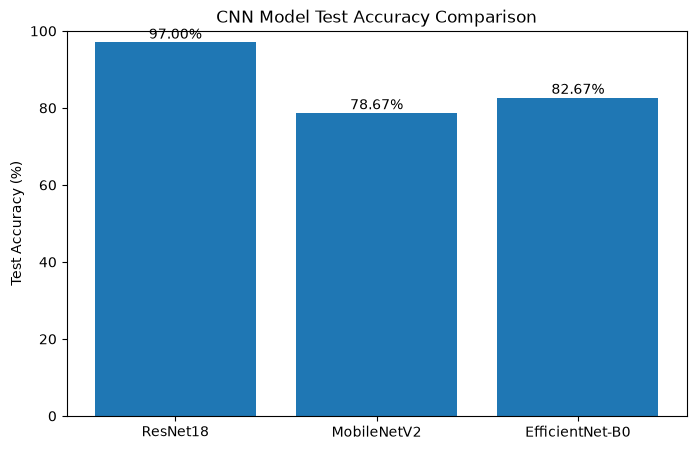

In [69]:
# 모델별 테스트 정확도 비교 그래프
import matplotlib.pyplot as plt

models_name = ["ResNet18", "MobileNetV2", "EfficientNet-B0"]
test_accuracy = [97.00, 78.67, 82.67]

plt.figure(figsize=(8, 5))
plt.bar(models_name, test_accuracy)

plt.title("CNN Model Test Accuracy Comparison")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)

# 막대 위에 정확도 표시
for i, value in enumerate(test_accuracy):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.show()

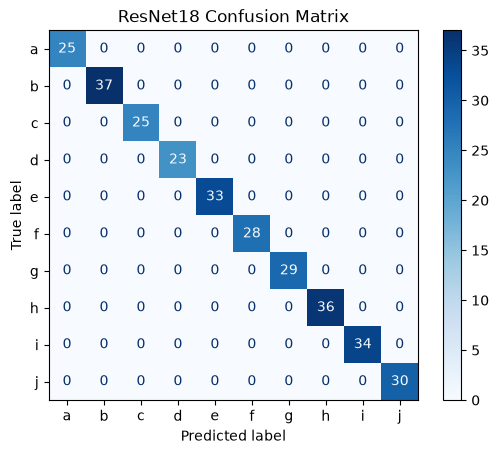

In [70]:
# ResNet18 혼동행렬 생성
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

model.eval()

all_labels = []
all_preds = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.numpy())
        all_preds.extend(predicted.cpu().numpy())

# 혼동행렬 계산
cm = confusion_matrix(all_labels, all_preds)

# 혼동행렬 시각화
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list("abcdefghij")
)

disp.plot(cmap="Blues")
plt.title("ResNet18 Confusion Matrix")
plt.show()

# a → d, h로 오인
# b → c로 오인
# c → h로 오인
# h → a, d로 오인
# i → f로 오인

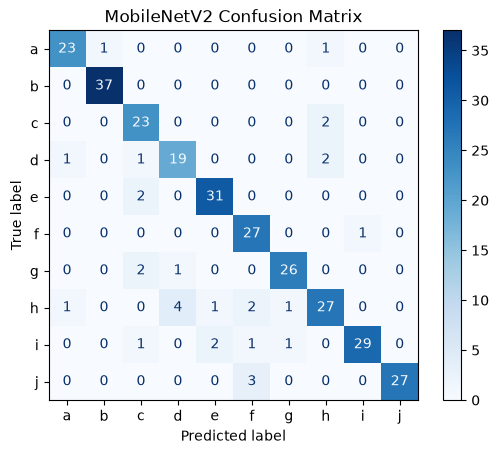

In [71]:
# MobileNetV2 혼동행렬 생성
model_mobilenet.eval()

all_labels = []
all_preds = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model_mobilenet(images)
        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.numpy())
        all_preds.extend(predicted.cpu().numpy())

# 혼동행렬 계산
cm = confusion_matrix(all_labels, all_preds)

# 혼동행렬 시각화
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list("abcdefghij")
)

disp.plot(cmap="Blues")
plt.title("MobileNetV2 Confusion Matrix")
plt.show()

# d → h : 4개 오분류
# g → h : 5개 오분류
# h → d : 4개 오분류
# c → g : 3개 오분류
# b → c : 3개 오분류

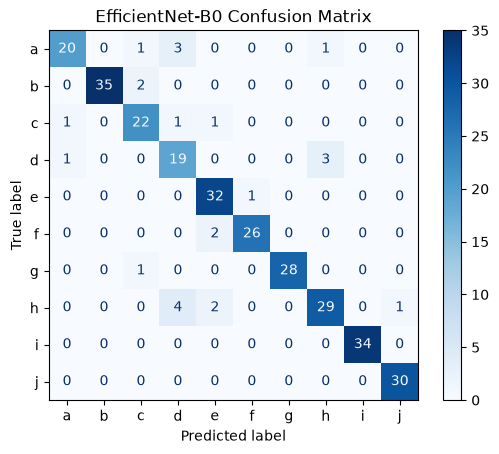

In [72]:
# EfficientNet-B0 혼동행렬 생성
model_efficient.eval()

all_labels = []
all_preds = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model_efficient(images)
        _, predicted = torch.max(outputs, 1)

        all_labels.extend(labels.numpy())
        all_preds.extend(predicted.cpu().numpy())

# 혼동행렬 계산
cm = confusion_matrix(all_labels, all_preds)

# 혼동행렬 시각화
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list("abcdefghij")
)

disp.plot(cmap="Blues")
plt.title("EfficientNet-B0 Confusion Matrix")
plt.show()

In [73]:
# 3개 모델의 Precision, Recall, F1-score 비교
from sklearn.metrics import precision_recall_fscore_support, accuracy_score

model_list = {
    "ResNet18": model,
    "MobileNetV2": model_mobilenet,
    "EfficientNet-B0": model_efficient
}

for model_name, current_model in model_list.items():
    current_model.eval()

    all_labels = []
    all_preds = []

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)

            outputs = current_model(images)
            _, predicted = torch.max(outputs, 1)

            all_labels.extend(labels.numpy())
            all_preds.extend(predicted.cpu().numpy())

    # 전체 성능 지표 계산
    precision, recall, f1, _ = precision_recall_fscore_support(
        all_labels, all_preds, average="weighted"
    )

    accuracy = accuracy_score(all_labels, all_preds)

    print(f"\n[{model_name}]")
    print(f"Accuracy : {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall   : {recall:.4f}")
    print(f"F1-score : {f1:.4f}")


[ResNet18]
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-score : 1.0000

[MobileNetV2]
Accuracy : 0.8967
Precision: 0.9008
Recall   : 0.8967
F1-score : 0.8967

[EfficientNet-B0]
Accuracy : 0.9167
Precision: 0.9208
Recall   : 0.9167
F1-score : 0.9173


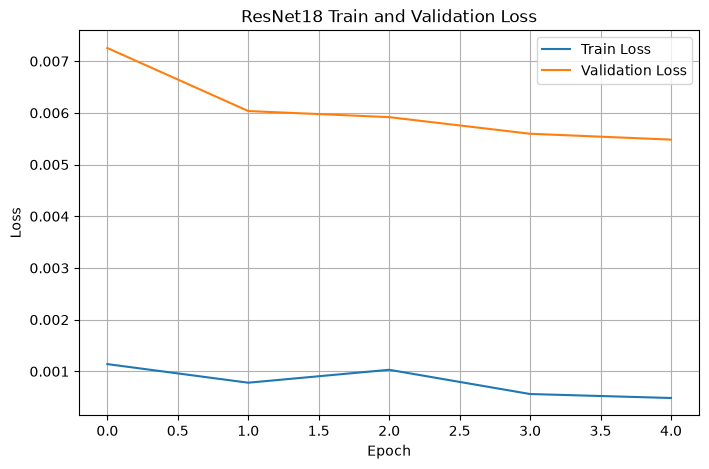

In [74]:
# ResNet18 학습 Loss와 검증 Loss 비교
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")

plt.title("ResNet18 Train and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)
plt.show()

# Train Loss: 약 0.001 → 0.0007
# Validation Loss: 약 0.048 → 0.044
# 학습 Loss가 계속 감소
# 검증 Loss도 전체적으로 감소

In [75]:
torch.save(model.state_dict(), "resnet18.pth")

print("ResNet18 모델 저장 완료!")

ResNet18 모델 저장 완료!


In [77]:
import torch
import torch.nn as nn
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = models.resnet18(weights=None)

model.fc = nn.Linear(model.fc.in_features, 10)

model.load_state_dict(
    torch.load("resnet18.pth", map_location=device)
)

model = model.to(device)
model.eval()

print("모델 불러오기 완료!")
print("사용 장치:", device)

모델 불러오기 완료!
사용 장치: cuda


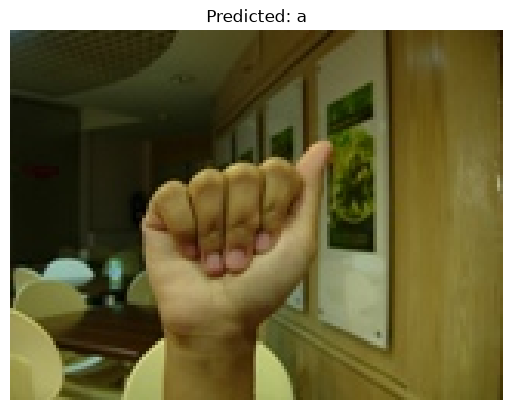

예측 클래스: a


In [78]:
from PIL import Image
import matplotlib.pyplot as plt

image_path = hand_path / "a (1).jpg"

image = Image.open(image_path).convert("RGB")
input_tensor = transform(image).unsqueeze(0).to(device)

with torch.no_grad():
    output = model(input_tensor)
    predicted_class = output.argmax(dim=1).item()

plt.imshow(image)
plt.title(f"Predicted: {chr(predicted_class + ord('a'))}")
plt.axis("off")
plt.show()

print("예측 클래스:", chr(predicted_class + ord('a')))